# 05 · 量子神经网络：鸢尾花分类

对应讲义实验 D · 约 40 分钟 · 前置：01 编程基础（第 5 节）

把数据编码进量子态，用参数化线路做分类器，与 MindSpore 联合训练；最后和经典模型比一比。

**学完本节，你将能够**
- 用编码线路把经典特征写进量子态；
- 搭建“编码线路 + 可训练线路 + 测量”的量子神经网络；
- 用经典基线客观评价量子模型。

In [1]:
import sys; sys.path.insert(0, "..")  # 仅参考答案需要：mqlab 位于上一级目录
import mqlab                         # 先导入：屏蔽 MindSpore 的冗长日志
import numpy as np
import mindspore as ms
from mindspore.dataset import NumpySlicesDataset
from mindspore.nn import SoftmaxCrossEntropyWithLogits, Adam
from mindspore.train import Model, Accuracy
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from mindquantum import IQPEncoding, HardwareEfficientAnsatz, X, RY
from mindquantum import Hamiltonian, QubitOperator, MQLayer, Simulator

## 1. 数据

取鸢尾花数据集的前两类（山鸢尾、变色鸢尾），共 100 个样本、4 个特征。IQP 编码线路需要 7 个输入：4 个特征本身，加上相邻特征的 3 个乘积（用于两比特相位项）。

In [2]:
iris = load_iris()
x = iris.data[:100].astype(np.float32)    # 前两类，100 个样本
y = iris.target[:100].astype(np.int32)
x = np.hstack([x, x[:, :3] * x[:, 1:4]])  # 加 3 个乘积 → 7 维
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)
print(x_train.shape, x_test.shape)

(80, 7) (20, 7)


## 2. 模型：编码线路 + 可训练线路 + 测量

- `IQPEncoding(4)`：H 之后用单比特和两比特相位写入 7 个特征，参数不训练；
- `HardwareEfficientAnsatz`：RY + CNOT，共 3 层，16 个可训练参数；
- 测量 $\langle Z_2\rangle$、$\langle Z_3\rangle$，作为两类的 logits。

7 个编码参数， 16 个可训练参数


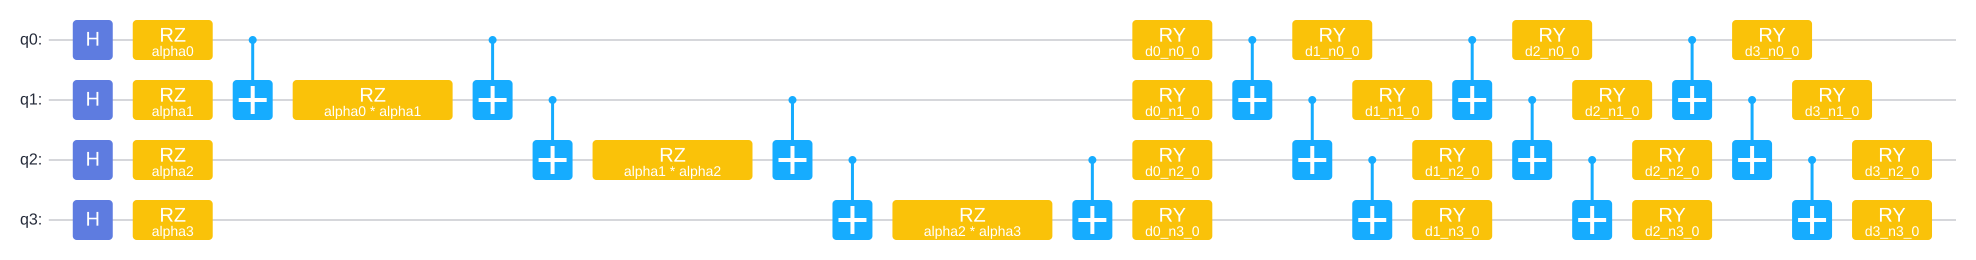

In [3]:
encoder = IQPEncoding(4).circuit                 # 7 个编码参数
ansatz = HardwareEfficientAnsatz(4, single_rot_gate_seq=[RY], entangle_gate=X, depth=3).circuit
circuit = encoder.as_encoder() + ansatz.as_ansatz()
print(len(encoder.params_name), '个编码参数，', len(ansatz.params_name), '个可训练参数')
circuit.svg()

In [4]:
ms.set_seed(1)
hams = [Hamiltonian(QubitOperator(f'Z{i}')) for i in (2, 3)]
sim = Simulator('mqvector', 4)
qnn = MQLayer(sim.get_expectation_with_grad(hams, circuit))   # 输出 ⟨Z2⟩、⟨Z3⟩

## 3. 训练

`MQLayer` 是标准的 MindSpore 网络层：损失函数、优化器、`Model.train` 都和经典深度学习完全一样。

In [5]:
loss = SoftmaxCrossEntropyWithLogits(sparse=True, reduction='mean')
opt = Adam(qnn.trainable_params(), learning_rate=0.1)
model = Model(qnn, loss, opt, metrics={'acc': Accuracy()})

train_ds = NumpySlicesDataset({'features': x_train, 'labels': y_train}, shuffle=False).batch(5)
test_ds = NumpySlicesDataset({'features': x_test, 'labels': y_test}, shuffle=False).batch(5)
model.train(20, train_ds)
print('量子神经网络测试准确率：', model.eval(test_ds)['acc'])

量子神经网络测试准确率： 1.0


## 4. 经典基线

评价量子机器学习，一定要有经典基线。

In [6]:
clf = LogisticRegression(max_iter=1000).fit(x_train, y_train)
print('逻辑回归测试准确率：', clf.score(x_test, y_test))

逻辑回归测试准确率： 1.0


两者都达到 100%：这两类鸢尾花线性可分，任务本身很简单。模型能学会，不等于比经典方法更好。

## 5. 现场改一改：先预测，再动手（开放练习）

三处修改，每一处先写下预测：

1. **换一个 Ansatz**：`Ansatz1(4, 2)`（`from mindquantum import Ansatz1`），同样 16 个参数，但没有纠缠门。测试准确率？　A 仍是 100%　B 降到 85%　C 降到 50%
2. **稳健性**：换 10 个随机种子（`ms.set_seed`），测试准确率稳定吗？　A 都是 100%　B 波动很大　C 约一半失败
3. **更难的任务**：改用变色鸢尾和维吉尼亚鸢尾（类别 1 和 2，它们不是线性可分的）。量子模型与逻辑回归，谁更好？　A 量子模型　B 差不多　C 逻辑回归

还可以继续试：`Ansatz2`，或把 depth 改为 1–5，比较测试准确率与参数个数。

In [7]:
# 练习：在这里尝试（提示：先把第 3 节的训练过程包装成函数）
### BEGIN SOLUTION
from mindquantum import Ansatz1

def train_qnn(x_tr, y_tr, x_te, y_te, ansatz_circ, seed=1, epochs=20):
    ms.set_seed(seed)
    c = encoder.as_encoder() + ansatz_circ.as_ansatz()
    net = MQLayer(Simulator('mqvector', 4).get_expectation_with_grad(hams, c))
    m = Model(net, loss, Adam(net.trainable_params(), learning_rate=0.1), metrics={'acc': Accuracy()})
    m.train(epochs, NumpySlicesDataset({'features': x_tr, 'labels': y_tr}, shuffle=False).batch(5))
    return m.eval(NumpySlicesDataset({'features': x_te, 'labels': y_te}, shuffle=False).batch(5))['acc']

# 练习 1：Ansatz1
a1 = Ansatz1(4, 2).circuit
print('Ansatz1：', len(a1.params_name), '个参数，测试准确率', train_qnn(x_train, y_train, x_test, y_test, a1))

# 练习 2：10 个随机种子
print('10 个种子：', [train_qnn(x_train, y_train, x_test, y_test, ansatz, seed=s) for s in range(10)])

# 练习 3：类别 1 与 2
x2 = iris.data[50:].astype(np.float32)
y2 = (iris.target[50:] - 1).astype(np.int32)
x2 = np.hstack([x2, x2[:, :3] * x2[:, 1:4]])
a_tr, a_te, b_tr, b_te = train_test_split(x2, y2, test_size=0.2, random_state=0)
print('类别 1 与 2：QNN', train_qnn(a_tr, b_tr, a_te, b_te, ansatz),
      '，逻辑回归', LogisticRegression(max_iter=1000).fit(a_tr, b_tr).score(a_te, b_te))
### END SOLUTION

Ansatz1： 16 个参数，测试准确率 0.85


10 个种子： [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


类别 1 与 2：QNN 0.7 ，逻辑回归 0.95


<details><summary>答案</summary>

1. B：85%。参数一样多，结构不同，效果也不同。
2. A：10 个种子都是 100%：在这个简单任务上，训练很稳定。
3. C：量子模型 70%，逻辑回归 95%。简单任务上看不出差别，任务一变难，经典基线明显更好。
</details>

## 小结

- 量子神经网络 = 编码线路 + 可训练线路 + 测量；在 MindSpore Quantum 中，它就是一个普通的网络层。
- 编码方式决定了数据如何进入量子态，往往比 Ansatz 更关键。
- 目前没有证据表明量子模型在实际数据上普遍优于经典模型：在系统的基准测试中，经典模型通常更好。把量子神经网络当作学习混合编程的练习，而不是性能承诺。